# Exercise 2.3

DISCLAIMER: All plotting have been generated with the help of AI tools (Copilot, Claude).

Solve the Korteweg-de Vries (KdV) equation using FFT

$u_t + u_{xxx} - u*u_x = 0$ with initial condition, $u(x,0) = sech(x)$

In [297]:
#Import relevant pacakages
import numpy as np
from scipy.integrate import solve_ivp, odeint
import matplotlib.pyplot as plt

With periodic and smooth functions, it can make sense to use Fourier Transformation to evaluate the derivatives. This is due to Fourier Transformation being based on periodic functions (sin(), cos()). The KdV is smooth and using the chosen initial value, the solution decays to zero quickly, meaning it is periodic in the domain.

The fast Fourier transform (`np.fft`) is used to compute the Fourier coefficients $\hat u_m$ of the grid values, such that $$u(x_j) = \frac1N\sum_m \hat u_m\, e^{i\kappa_m x_j}$$

This is defined on the interval $x\in[-L/2, L/2)$ with $L=200$ and $N=512$ with $x_j = -L/2 + jL/N$ and assumed periodic such that $x_0 = x_N$.

By using the Fourier Transform, the PDE can be transformed to a system of ODE's, which can be solved by ODE's solvers as `solve_ivp`.

Given the chosen domain, $\lambda_m = L/m$, the wavenumbers are found using the `np.fft.fftfreq()` function, which gives the discrete frequencies, $\kappa$.
$$\kappa_m = \frac{2\pi}{\lambda_m} = \frac{2\pi m}{L}.$$
In the code these are `2*np.pi*np.fft.fftfreq(n, d=dx)`.

Differentiating a term $e^{i\kappa x}$ multiplies it by $i\kappa$, so derivatives become multiplications in Fourier space:
$$\widehat{u_x} = i\kappa\,\hat u, \qquad \widehat{u_{xxx}} = (i\kappa)^3\,\hat u$$

Discretizing only in space turns the PDE into a system of ODEs, $\dot{\mathbf u} = F(\mathbf u)$ (the method of lines), which is integrated in time with `scipy.integrate.solve_ivp`. The BDF method is used because the $u_{xxx}$ term makes the system stiff.


In [298]:
L = 200 # domain length
n = 512 # number of evaluations (number of grid points)
dx = L/n # step length
x = np.linspace(-L/2, L/2, n, endpoint=False) # define x domain


kappa = 2*np.pi * np.fft.fftfreq(n, d = dx) # frequencies, discrete ordered wavenumbers

def rhsKdV(t, u, kappa):
    uhat  = np.fft.fft(u)                       # to fourier state for u
    duhat = 1j*kappa * uhat                     # to fourier state for u_x
    ddduhat = np.power((1j * kappa),3) * uhat   # to fourier state for u_xxx
    
    ux = np.fft.ifft(duhat)                     # Back to physical space for u_x
    uxxx = np.fft.ifft(ddduhat)                 # Back to physical space for u_xxx
    return (u*ux - uxxx).real                   # Returns only the real part of the solution

# initial condition
u0 = 1/np.cosh(x) 

T = 50 # Final time
nT = 501 # Number of samples
t = np.linspace(0, T, nT)
t_span = (0,T)
ut = solve_ivp(rhsKdV, t_span, u0, method = "BDF", t_eval = t, args = (kappa,)) # BDF is used as the system is stiff

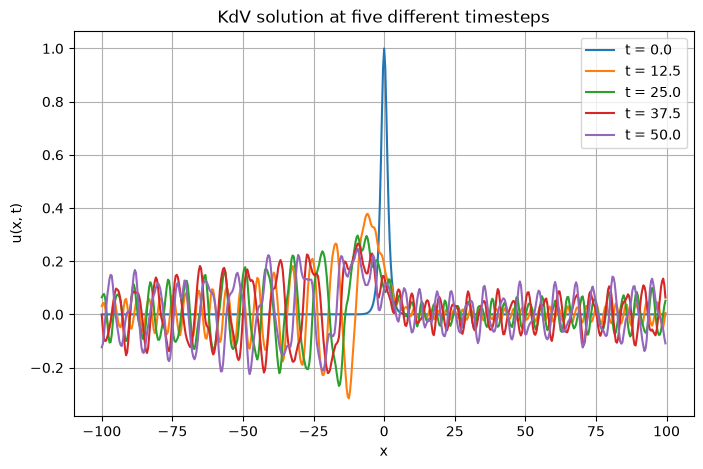

In [299]:
# Plot the solution in x for five different timesteps
indices = np.linspace(0, len(t) - 1, 5, dtype=int)

plt.figure(figsize=(8, 5))

for index in indices:
    plt.plot(x, ut.y[:, index], label=f"t = {t[index]:.1f}")

plt.xlabel("x")
plt.ylabel("u(x, t)")
plt.title("KdV solution at five different timesteps")
plt.grid(True)
plt.legend()
plt.show()
plt.show()

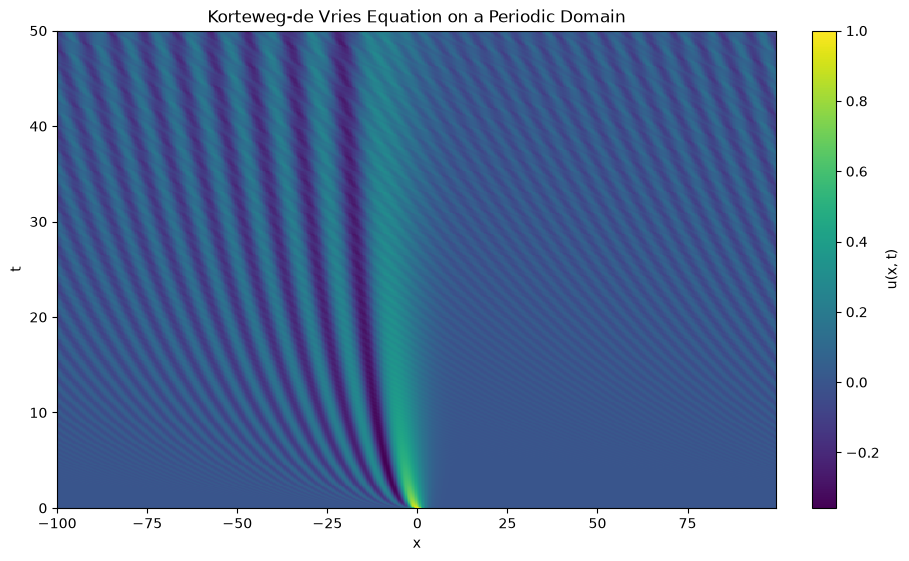

In [300]:
# Heatmap of the solution
fig, ax = plt.subplots(figsize=(9, 5.5), constrained_layout=True)

plot = ax.pcolormesh(
    x,
    t,
    ut.y.T,
    shading="auto",
    cmap="viridis"
)

ax.set_xlabel("x")
ax.set_ylabel("t")
ax.set_title("Korteweg-de Vries Equation on a Periodic Domain")
ax.set_xlim(x.min(), x.max())
ax.set_ylim(t.min(), t.max())

colorbar = fig.colorbar(plot, ax=ax)
colorbar.set_label("u(x, t)")

plt.show()


# Exercise 2.4

Solve the Kuramoto-Sivashinsky (KS) equation using FFT

u_t + u_xx +u_xxxx + 1/2 u_x^2 = 0 with initial condition, u(x,0) = sech(x)

Here the same method is used as in Exercise 2.3

In [306]:
L = 200 # length of evaluation
n = 512 # number of evaluations
dx = L/n # step length
x = np.linspace(-L/2, L/2, n, endpoint=False)


kappa = 2*np.pi * np.fft.fftfreq(n, d = dx) # frequencies, ordered wavenumbers

def rhsKS(t, u, kappa):
    uhat  = np.fft.fft(u)                       # to fourier state for u
    duhat = np.power((1j * kappa),1) * uhat     # to fourier state for u_xx
    dduhat = np.power((1j * kappa),2) * uhat    # to fourier state for u_xx
    dddduhat = np.power((1j * kappa),4) * uhat  # to fourier state for u_xxxx
    
    ux = np.fft.ifft(duhat)                    # back to phisical state for u_x
    uxx = np.fft.ifft(dduhat)                    # back to phisical state for u_xx
    uxxxx = np.fft.ifft(dddduhat)               # back to phisical state for u_xxxx
    return (-uxx - uxxxx - 1/2*ux**2).real      # Returns only the real part of the solution

# initial condition
u0 = 1/np.cosh(x) 

T = 25
nT = 251
t = np.linspace(0, T, nT)
t_span = (0,T)
ut = solve_ivp(rhsKS, t_span, u0, method = "BDF", t_eval = t, args = (kappa,))

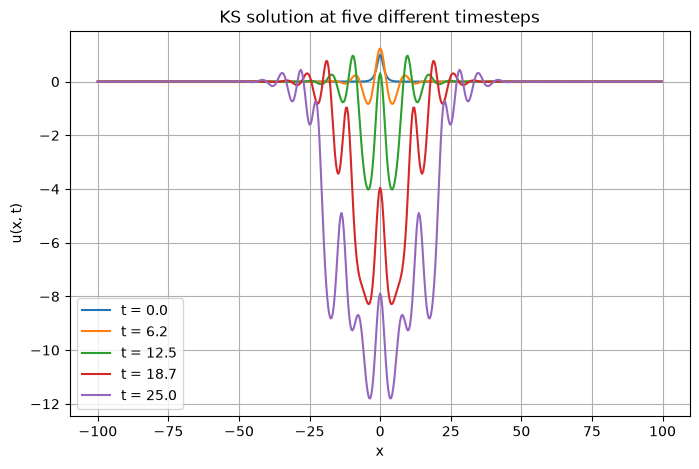

In [307]:
# Plot the solution in x for five different timesteps
indices = np.linspace(0, len(t) - 1, 5, dtype=int)

plt.figure(figsize=(8, 5))

for index in indices:
    plt.plot(x, ut.y[:, index], label=f"t = {t[index]:.1f}")

plt.xlabel("x")
plt.ylabel("u(x, t)")
plt.title("KS solution at five different timesteps")
plt.grid(True)
plt.legend()
plt.show()
plt.show()

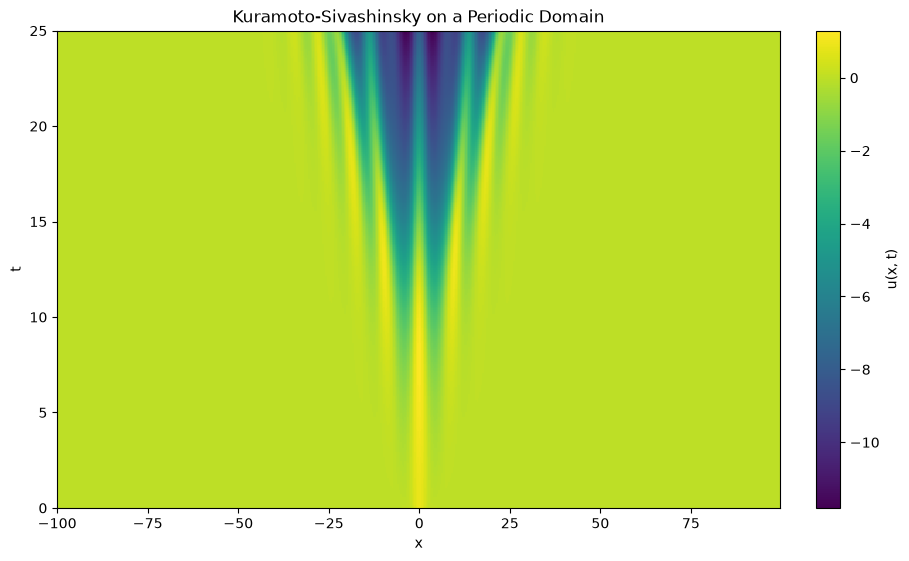

In [308]:
# Heatmap of the solution
fig, ax = plt.subplots(figsize=(9, 5.5), constrained_layout=True)

plot = ax.pcolormesh(
    x,
    t,
    ut.y.T,
    shading="auto",
    cmap="viridis"
)

ax.set_xlabel("x")
ax.set_ylabel("t")
ax.set_title("Kuramoto-Sivashinsky on a Periodic Domain")
ax.set_xlim(x.min(), x.max())
ax.set_ylim(t.min(), t.max())

colorbar = fig.colorbar(plot, ax=ax)
colorbar.set_label("u(x, t)")

plt.show()

# Exercise 12.2

Only a

In this exercise the Kuramoto-Sivashinsky (KS) equation is used again. In the previous exercise this equation was solved and the solution in now used to create a Galerkin-Projection which are tested for future state-predictions.

In [332]:
# KS solution:
t = ut.t
u_t = ut.y

In [333]:
# POD using Economy SVD for an r capturing 99.9% of solution
Uhat, Shat, VThat = np.linalg.svd(u_t, full_matrices=False)

# Find cumulative energy for plot using Frobenius norm
energy_cum = np.cumsum(Shat**2) / np.sum(Shat**2)

#Find rank for 99% of captured solution:
r999 = np.argmax(energy_cum >= 0.999) + 1
print(f"To capture 99.9% of the solution a rank of r={r999} has to be used")

To capture 99.9% of the solution a rank of r=5 has to be used


Now a rank-r Galerkin approximation of the evolution is found by setting $\tilde{U} = \Psi$ where $\tilde{U} \in R^{r=26}$

The Galerkin expansion is $u(t) \approx \Psi a(t)$. The Fourier-Spectral Method is used to solve the system by converting the truncated SVD modes into the fourier basis. 

However, now the Reduced-Order Model (ROM) formulation in used to divide into linear and none-linear for a Galerkin Projection part:

$\frac{a(t)}{dt} = \Psi^TL\Psi a(t) + \Psi^T N(\Psi a(t),\beta)$

where L is a linear operator in this case the linear part is $- u_{xx} - u_{xxxx}$ so the linear operator $ L = - \partial_{xx} - \partial_{xxxx}$

making $L\Psi = -\frac{\partial^2 \Psi}{\partial x^2} - \frac{\partial^4 \Psi}{\partial x^4}$

and the rest is none-linear, so $N(u) = -\frac{1}{2} u_x^2$






The solution is found on the same domain as in exercise 2.4.

In [334]:
# Setting up the function to return the reduced evolution
def rhsGalerkinKS(t, a, Psi, kappa):
    # Converting the modes into fourier space
    Psihat  = np.fft.fft(Psi, axis=0)
    dPsihat = np.power((1j * kappa),1) * Psihat
    ddPsihat = np.power((1j * kappa),2) * Psihat
    ddddPsihat = np.power((1j * kappa),4) * Psihat 

    # Converting back to physical space
    dPsi    = np.fft.ifft(dPsihat, axis=0).real
    ddPsi   = np.fft.ifft(ddPsihat, axis=0).real
    ddddPsi = np.fft.ifft(ddddPsihat, axis=0).real

    # Computing the linear operator Lr = \Psi^T L\Psi
    Lr = Psi.T @ (- ddPsi - ddddPsi)
    ux = dPsi @ a
    return Lr @ a - Psi.T @ (1/2*ux**2)  # Returning reduced evolution  

In [335]:
# Solving the system the same way as in Exercise 2.4 using r:99.9% and r = 30
# same domain as exercise 2.4
L = 200 # length of evaluation
n = 512 # number of evaluations
dx = L/n # step length
x = np.linspace(-L/2, L/2, n, endpoint=False)

kappa = 2*np.pi * np.fft.fftfreq(n, d = dx) # frequencies, ordered wavenumbers
kappa = kappa[:, None]

T = 25
nT = 251
t = np.linspace(0, T, nT)
t_span = (0,T)
r_list = [r999, 15]
Galerkin_predictions = []
for i in range(len(r_list)):
    #Setting up the truncated modes
    Psi = Uhat[:, :r_list[i]]

    # Initial condition taken from ut
    a0 = Psi.T @ u_t[:,0]


    at = solve_ivp(rhsGalerkinKS, t_span, a0, method = "BDF", t_eval = t, args = (Psi, kappa,))

    ut_Galerkin = Psi @ at.y
    Galerkin_predictions.append(ut_Galerkin)

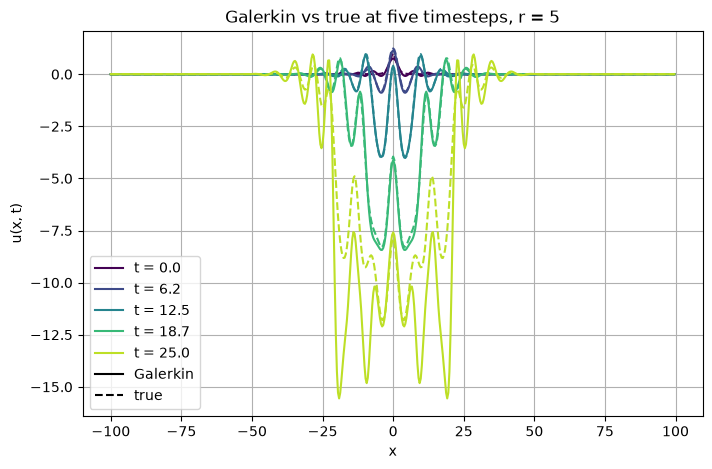

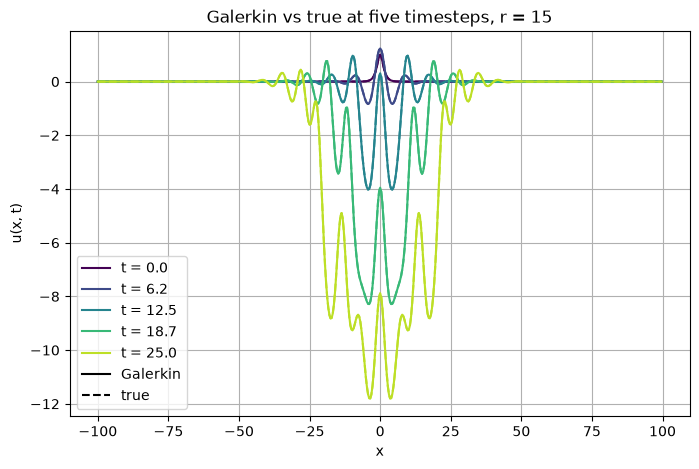

In [336]:
for ut_Galerkin, r_i in zip(Galerkin_predictions, r_list):
    nt_i = ut_Galerkin.shape[1]              # < len(t) if the solver stopped early
    idx = indices[indices < nt_i]

    # Snapshots in x: Galerkin (solid) vs true (dashed)
    plt.figure(figsize=(8, 5))
    colors = plt.cm.viridis(np.linspace(0, 0.9, len(idx)))
    for c, index in zip(colors, idx):
        plt.plot(x, ut_Galerkin[:, index], color=c, label=f"t = {t[index]:.1f}")
        plt.plot(x, u_t[:, index], "--", color=c)
    plt.plot([], [], "k-", label="Galerkin")
    plt.plot([], [], "k--", label="true")
    plt.xlabel("x")
    plt.ylabel("u(x, t)")
    plt.title(f"Galerkin vs true at five timesteps, r = {r_i}")
    plt.grid(True)
    plt.legend()
    plt.show()

From this it can be seen that it is possible to use the Galerkin-Projections at least by reducing the 251 snapshots to only 15 to reproduce the true projections. 

With only 5 snapshots (capturing 99.9% of the solution) it is not perfect but seems to follow the trajectory quite well. It overshoots the trajectory at time = 25, but do capture the chaotic behaviour that expands over time.